# Thoughts on diffrax vs DifferentialEquations.jl

This notebook covers my reflections on diffrax vs DifferentialEquations.jl for dynamic ODE-based workflows. In particular, it covers scenario where I expect each software to excel.

## Background 

This section covers background on DifferentialEquations.jl, diffrax and automatic differentiation.

### DifferentialEquations

DifferentialEquations.jl is a well-established part of the Julia ecosystem and its core functionality has been available since 2017. Key components include:

- **[OrdinaryDiffEq.jl](https://github.com/SciML/OrdinaryDiffEq.jl)**: This package provides a wide range of ODE solvers for both small and large systems. It contains both stiff and non-stiff solvers.
- **[ModelingToolkit.jl](https://github.com/SciML/ModelingToolkit.jl)**: Allows for symbolic pre-processing of models, which with other things allows for automatic Jacobian computations of the model's right-hand side.
- **[LinearSolve.jl](https://github.com/SciML/LinearSolve.jl)**: Contains high-performance linear solvers, both from Julia and non-Julia sources. A crucial component for solving stiff systems.
- **[SciMLSensitivity.jl](https://github.com/SciML/SciMLSensitivity.jl)**: Contains methods for computing gradients via both forward and adjoint methods for ODE models. For adjoint methods it primarily supports the optimize-then-discretize approach, which involves solving an adjoint ODE system backward in time.
- **[Lux.jl](https://github.com/LuxDL/Lux.jl)**: Contains methods for neural networks. These data-driven models can be integrated into ODE-models, and soon hopefully also into ModelingToolkit models (see [here](https://github.com/SciML/ModelingToolkitNeuralNets.jl)).

The core components of the DifferentialEquations.jl ecosystem are mature, for example both the ODE solvers and ModelingToolkit.jl are used in several industry applications. The maintenance of these packages is primarily handled by researchers at JuliaHub that have a stable position.

However, the ecosystem is in my opinion overstretched, hence some packages are not up to desired standard. Particularly, SciMLSensitivity.jl seems to lack a knowledgeable core maintainer. Additionally, packages like Optimization.jl need more maintainers. This situation largely stems from the fact that many packages are initially created and maintained by academics, and when the original creators move on the package maintenance falls between the chairs. 

### diffrax

The diffrax suite, part of Patrick Kidger's SciML universe in Jax. The core packages with respect to ODE modeling are:

- **[diffrax](https://github.com/patrick-kidger/diffrax)**: This suite provides numerical ODE solvers compatible with Jax. Notably, these solvers are designed to support adjoint sensitivity analysis using the discretize-then-optimize approach. For Hessian computations, the package also supports the reverse-over-forward method.
- **[equinox](https://github.com/patrick-kidger/equinox)**: A package for creating neural networks within Jax. These data-driven models can quite easily be integrated into diffrax models.
- **[lineax](https://github.com/patrick-kidger/lineax)**: A package for solving linear systems in Jax. It serves as the backend for stiff solvers in diffrax.

Although diffrax is newer and therefore less extensively tested than DifferentialEquations.jl, it is cleverly designed to leverage the strengths of Jax, particularly with respect to automatic differentiation. This aspect potentially makes diffrax suitable for larger models with many parameters. A red flag might be maintenance, because outside of Patrick Kidger, I do not know if there is any core maintainer (or industry maintainers).

### Forward mode automatic differentiation

In forward mode automatic differentiation the directional derivative of a function $G(x)$ along a vector 
$\mathbf{r}$, $\nabla_{\mathbf{r}} G = \langle \nabla G, \mathbf{r} \rangle$, is computed simultaneously as the objective value $y = G(x)$. As a working example, consider the function 

$$
  y = g(x_1, x_2) = \big( \mathrm{ln}(x_1) + x_1 x_2 - sin(x_2) \big)^2.
$$

When calculating a function such as $g$, we navigate a computational graph to compute the components $v_i$ that constitute $g$. In forward mode automatic differentiation (AD), alongside each $v_i$, we compute the tangents $\dot{v}_i = \nabla_{\mathbf{r}} g_{v_i}$ during the forward traversal. As a practical example, let $[x_1, x_2] = [2, 0.5]$ and $r = [0.5, 0.5]$:

| Forward trace | Tangent trace |
|---------|:-----|
| $v_{-1} = x_1 = 2$ | $\dot{v}_{-1} = \nabla_{\mathbf{r}} x_1 = r_1 = 0.5$   |
| $v_{0} = x_2 = r_2 = 5$     | $\dot{v}_{0} = \nabla_{\mathbf{r}} x_2 = 0.5$ |
| $v_{1} = \mathrm{ln}(v_{-1}) = \mathrm{ln}(2)$| $\dot{v}_{1} = \nabla_{\mathbf{r}} \mathrm{ln}(v_{-1}) = \frac{\dot{v}_{-1}}{v_{-1}} = 0.25$    |
| $v_{2} = v_{-1} v_0 = 10$| $\dot{v}_2 = \nabla_{\mathbf{r}} v_{-1}v_0  = \dot{v}_{-1} v_0 + \dot{v}_0 v_{-1} = 3.5$    |
| $v_{3} = \mathrm{sin}(v_{0}) = \mathrm{sin}(5)$| $\dot{v}_3 = \nabla_{\mathbf{r}} \mathrm{sin}(v_0) = \dot{v}_0 \mathrm{cos}(v_0) \approx 0.14$|
| $v_{4} = v_1 + v_2 \approx 10.69$| $\dot{v}_4 = \nabla_{\mathbf{r}} v_1+v_2 = \dot{v}_1 + \dot{v}_2 = 3.75$    |
| $v_{5} = v_4 - v_3 \approx 11.65$| $\dot{v}_5 = \nabla_{\mathbf{r}} v_4-v_3 = \dot{v}_4 - \dot{v}_3 \approx 3.61$ |
| $v_{6} = v_5^2 \approx 135.77$| $\dot{v}_6 = \nabla_{\mathbf{r}} v_5^2 = 2v_5 \dot{v}_5 \approx 84.09$|

At each stage in the tangent trace we make use of elementary differentiation rules, and the chain rule;

$$
\dot{w}_i = \sum_{j \in \mathcal{A}} \frac{\partial w_i}{\partial w_k} \dot{w}_k,
$$

where $\mathcal{A}$ is the set of nodes going into node $i$. All-to-all, with the tangent trace from a single forward-pass we can compute $\nabla_{\mathbf{r}} f = \langle \nabla f(\mathbf{x}), \mathbf{r} \rangle$. By doing $n$ forward passes using the basis vectors $\mathbf{r} = \mathbf{e_1}, \ldots, \mathbf{e}_n$ we can compute the gradient at point $\mathbf{x}$.

A natural question is, how do we perform forward mode AD in practice? We make use of dual numbers which are defined as; $a = a_1 + a_2 \epsilon$ where $\epsilon^2 = 0$. Consider $g : \mathbb{R} \rightarrow \mathbb{R}$. If we Taylor expand around $\tilde{x} = a_1$ and evaluate at $\tilde{x} = a_1 + a_2 \epsilon$ we obtain; 

$$
  g(a_1 + a_2 \epsilon) = g(a_1) + g'(a_1) a_2 \epsilon + \mathcal{O}\underbrace{(\epsilon^2)}_{=0} = g(a_1) + g'(a_1)a_2\epsilon.
$$

This simple Taylor expansion based proof shows that when we apply a function g to a dual number the dual part evaluates to the directional derivative $g'(a_1) a_2$. This means that if the function $g$ can be broken down into elementary operations (e.g, sin, cos, exp, plus, minus etc...) and we can define rules for dual numbers in a programming language, e.g. define `sin(A::Dual)` as 

$$
  \mathrm{sin}(a_1 + a_2 \epsilon) = \mathrm{sin}(a_1) + a_2 \mathrm{cos}(a_1) \epsilon,
$$

we can compute $g(a_1 + a_2\epsilon) = \big(g(a_1), a_2 g'(a_1)a_2\big)$ from a single forward pass of $g$. In Julia this functionality is given by [ForwardDiff.jl](https://github.com/JuliaDiff/ForwardDiff.jl). 

For a multivariate function $g : \mathbb{R}^{n} \rightarrow \mathbb{R}$ we use dual numbers on the form; $\mathbf{a} + \mathbf{d}$ where $\mathbf{d} = \mathbf{b}\cdot \pmb{\epsilon} = [b_1 \epsilon_1 \ldots b_n \epsilon_n]$ (note here $\cdot$ is elementvise multiplication) where following definition $\epsilon_i \epsilon_j = 0 \ \forall i,j$. If we Taylor expand $g$ around $\mathbf{a}$ and evaluate at $\mathbf{a} + \mathbf{b} \cdot \pmb{\epsilon}$ we obtain 

$$
    f(\mathbf{a} + \mathbf{b} \cdot \pmb{\epsilon}) = f(\mathbf{a}) + \langle \nabla f(\mathbf{a}), \mathbf{b} \rangle \epsilon + \mathcal{O}\underbrace{(\epsilon^2)}_{=0}.
$$

Again we see that the dual part evaluates to the directional derivative.

For completeness, it should be noted that forward mode automatic differentiation (AD) can be used for vector functions $g : \mathbb{R}^n \rightarrow \mathbb{R}^m$. In this context, a single forward pass efficiently computes $\mathbf{J} \mathbf{r}$, the Jacobian-vector product (JVP), without explicitly constructing the Jacobian.

### Reverse mode automatic differentiation

In reverse mode automatic differentiation the gradient $\nabla f$ is directly computed from a backward pass of the program. Specifically, in our program at each stage we compute the sensitivity of the output to a node $v_i$. Using the chain rule we have;

$$
  \frac{\partial y}{\partial v_i} = \sum_{j \in \mathcal{B}} \frac{\partial y}{\partial v_j} \frac{\partial v_j}{\partial v_i} = \sum_{j \in \mathcal{B}} \bar{v}_j \frac{\partial v_j}{\partial v_i}, 
$$

where $\mathcal{B}$ is the set of children to node $v_i$. Above follows from the fact that the only way $v_i$ can affect $y$ is via its children, and as long as we can compute $\bar{v_i}$ for the last node (output node) we can compute the gradient. Let us again consider the function $y = \big( \mathrm{ln}(x_1) + x_1x_2 - sin(x_2) \big)^2$, where we seed the reverse pass with $\mathbf{r} = [1]$.

| Forward trace | Reverse (adjoint) trace |
|---------|:-----|
| $v_{-1} = x_1 = 2$ | $\bar{v}_{-1} = \bar{v}_2 \frac{\partial v_2}{v_{-1}} + \bar{v}_{1} \frac{\partial v_1}{\partial v_{-1}} = \bar{v}_2v_0 + \bar{v}_1 \frac{1}{v_{-1}} \approx 128.2$   |
| $v_{0} = x_2 = r_2 = 5$     | $\bar{v}_0 = \bar{v}_2 \frac{\partial v_2}{\partial v_0} + \bar{v}_3 \frac{\partial v_3}{\partial v_0} = \bar{v}_2v_{-1} + \bar{v}_3\mathrm{cos}(v_0) \approx 40.0$ |
| $v_{1} = \mathrm{ln}(v_{-1}) = \mathrm{ln}(2)$| $\bar{v}_1 = \bar{v}_4 \frac{\partial v_4}{\partial v_1} \approx 23.3$    |
| $v_{2} = v_{-1} v_0 = 10$| $\bar{v}_2 = \bar{v}_4 \frac{\partial v_4}{\partial v_2} \approx 23.3$    |
| $v_{3} = \mathrm{sin}(v_{0}) = \mathrm{sin}(5)$| $\bar{v}_3 = \bar{v}_5 \frac{\partial v_5}{\partial v_3} \approx -23.3$|
| $v_{4} = v_1 + v_2 \approx 10.69$| $\bar{v}_4 = \bar{v}_5\frac{\partial v_5}{\partial v_4} \approx 23.3$    |
| $v_{5} = v_4 - v_3 \approx 11.65$| $\bar{v}_5 = \bar{v}_6 \frac{\partial v_6}{\partial v_5} = \bar{v}_6 2 v_5 \approx 23.3$ |
| $v_{6} = v_5^2 \approx 135.77$| $\bar{y} = \bar{v}_6 = 1$|

Overall, we find that $\nabla f(2, 5) = [128.2, 40.0]$ from a single reverse pass.

For small models reverse mode automatic differentiation is slower than forward mode due to overhead of creating the tape/trace of the forward computations. For larger models ($\geq 50$ parameters) reverse mode is often faster because in contrast to forward mode only two passes of the code are required.

When doing the backward trace in practice we actually compute the product;

$$
  \nabla f = 
  \begin{bmatrix}
  \frac{\partial y}{\partial x_1} \\ 
  \vdots \\ 
  \frac{\partial y}{\partial x_n}
  \end{bmatrix}
  \begin{bmatrix}
  r_1
  \end{bmatrix},
$$

and for multivariate function $f \mathbb{R}^n \rightarrow \mathbb{R}^m$ a single reverse pass computes the vector Jacobian product (VJP)

$$
  \mathrm{VJP} = 
  \begin{bmatrix}
  \frac{\partial y_1}{\partial x_1} & \cdots & \frac{\partial y_1}{\partial x_n} \\ 
  \vdots & \ddots & \vdots \\
  \frac{\partial y_m}{\partial x_1} & \cdots & \frac{\partial y_m}{\partial x_n} \\ 
  \end{bmatrix}^{\mathrm{T}}
  \begin{bmatrix}
  r_1 \\ \vdots \\ r_m 
  \end{bmatrix}
  = 
  \mathbf{J}^{\mathrm{T}} \mathbf{r} = 
  \mathbf{r}^{\mathrm{T}} \mathbf{J}.
$$

Reverse mode automatic differentiation (AD) can be implemented by tracing the forward pass with a data structure. This allows the subsequent computation of adjoints for elementary functions using basic derivative rules. Tracing every operation in reverse mode automatic differentiation (AD) can be resource-intensive however, particularly with code that changes the number of executions per forward pass, such as adaptive ODE solvers (here we cannot compile a static graph). To mitigate this, one alternative is using source code transformation combined with predefined rules. For example, consider the dot product $y = \langle \mathbf{v}_i, \mathbf{a} \rangle$ where $\mathbf{a}$ is constant. Instead of computing the adjoint through basic operations, we can apply a rule that $\bar{\mathbf{v}}_i = \bar{y} [a_1 \mathbf{v}_i^{(1)} \cdots a_n \mathbf{v}_i^{(n)}]$, which is triggered during the reverse pass when a dot product is encountered. Further, for handling dynamic code structures like loops, tools such as the Jax scan function can be utilized. This function applies a given operation across a vector input, tracing only the function itself and the input and output vectors it operates over. This approach efficiently generates reverse-pass code by avoiding the need to save each loop iteration.

### Implementation in DifferentialEquations.jl and diffrax 

#### Forward mode

Both diffrax and DifferentialEquations.jl support forward mode automatic differentiation, using dual numbers via ForwardDiff.jl for Julia and Jax for the diffrax. Based on my experience, ForwardDiff.jl is a mature and high-performing package in the Julia ecosystem. Therefore, as long as diffrax ODE solvers are not faster than those in Julia, I do not expect it to outperform DifferentialEquations.jl in the smaller model regime. This is because forward-mode AD is easier to implement because it only involves propagating dual numbers through the computational graph, therefore certain code-patterns like for-loops do not negatively impact performance. This contrasts with reverse-mode AD, which typically is not performant with respect to loops as the context of each loop-pass must be saved into the computational graph. In short, forward-mode AD is more forgiving with respect of how the code is written, and it supports efficient operations such as in-place mutations.

#### Reverse mode

Both Diffrax and DifferentialEquations.jl support reverse mode automatic differentiation: Diffrax uses Jax, while DifferentialEquations.jl uses Zygote.jl.

Jax, in my view, is the better tool for reverse-mode AD. It prioritizes performance by focusing on a subset of functionalities rather than supporting the entire Python language. For instance, Jax does not directly support reverse AD with while-loops, and for for-loops encourages the use of the scan function. 

In contrast, Zygote.jl supports a wide array of Julia language features, including loops. However, this broad compatibility can lead to performance issues. Loops are inefficient in Zygote, and for more advanced functionality (e.g. linear solving) rules must be implemented. As a result, few ODE solvers in Julia directly support reverse-mode AD through Zygote, and for those that do, it is inefficient. Instead, when an ODE solve is encountered in the reverse pass custom rules that defer to methods in SciMLSensitivity are used.

Julia also offers other reverse-mode AD packages like Diffractor.jl and Enzyme.jl. Diffractor.jl operates similarly to Zygote and is unlikely to enhance efficiency in reverse-mode AD for Julia's ODE solvers without significant rewrites to ODE solvers. Enzyme, on the other hand, operates at the LLVM compiler level, however, it is challenging to get it working for more complex code (for example, currently it cannot handle neural networks in the ODE right-hand site). 

In summary, direct reverse-mode AD for ODE solvers in Julia may take quite some time (years). The existing solvers were not designed with reverse-mode AD in mind, unlike the case Diffrax. Hence, adding direct reverse-mode, or making the solvers compatible with it, would be a challenge (would likely involve writing a lot of custom rules). Additionally, the general-purpose nature of Julia's reverse-mode packages does not cater to efficiently managing adaptive code such as adaptive ODE solvers, for example Zygote does not have anything that corresponds to the Jax scan function (the scan function is used in the diffrax while-loop when solving the ODE). Therefore, if diffrax adjoint approach is much better than the approach in SciMLSensitivity, diffrax might be the best alternative for models with many parameters ($\geq 75$ parameters).

## Benchmarks

This section first consider benchmarks for ODE solvers, followed by benchmarks for computing gradients for Universal Differential Equations (UDEs) where the model right-hand side of the model contains a neural network.

### ODE solvers

To evaluate the diffrax stiff and non-stiff solvers I considered five classical benchmark examples. Two non-stiff models; the Lotka-Volttera model (2 ODEs) and the Rigid-body problem (3 ODE:s), and three stiff models; the Rober model (3 ODEs), the Hires model (8 ODEs) and the Pollu model (20 ODEs).

Starting with the non-stiff solvers:

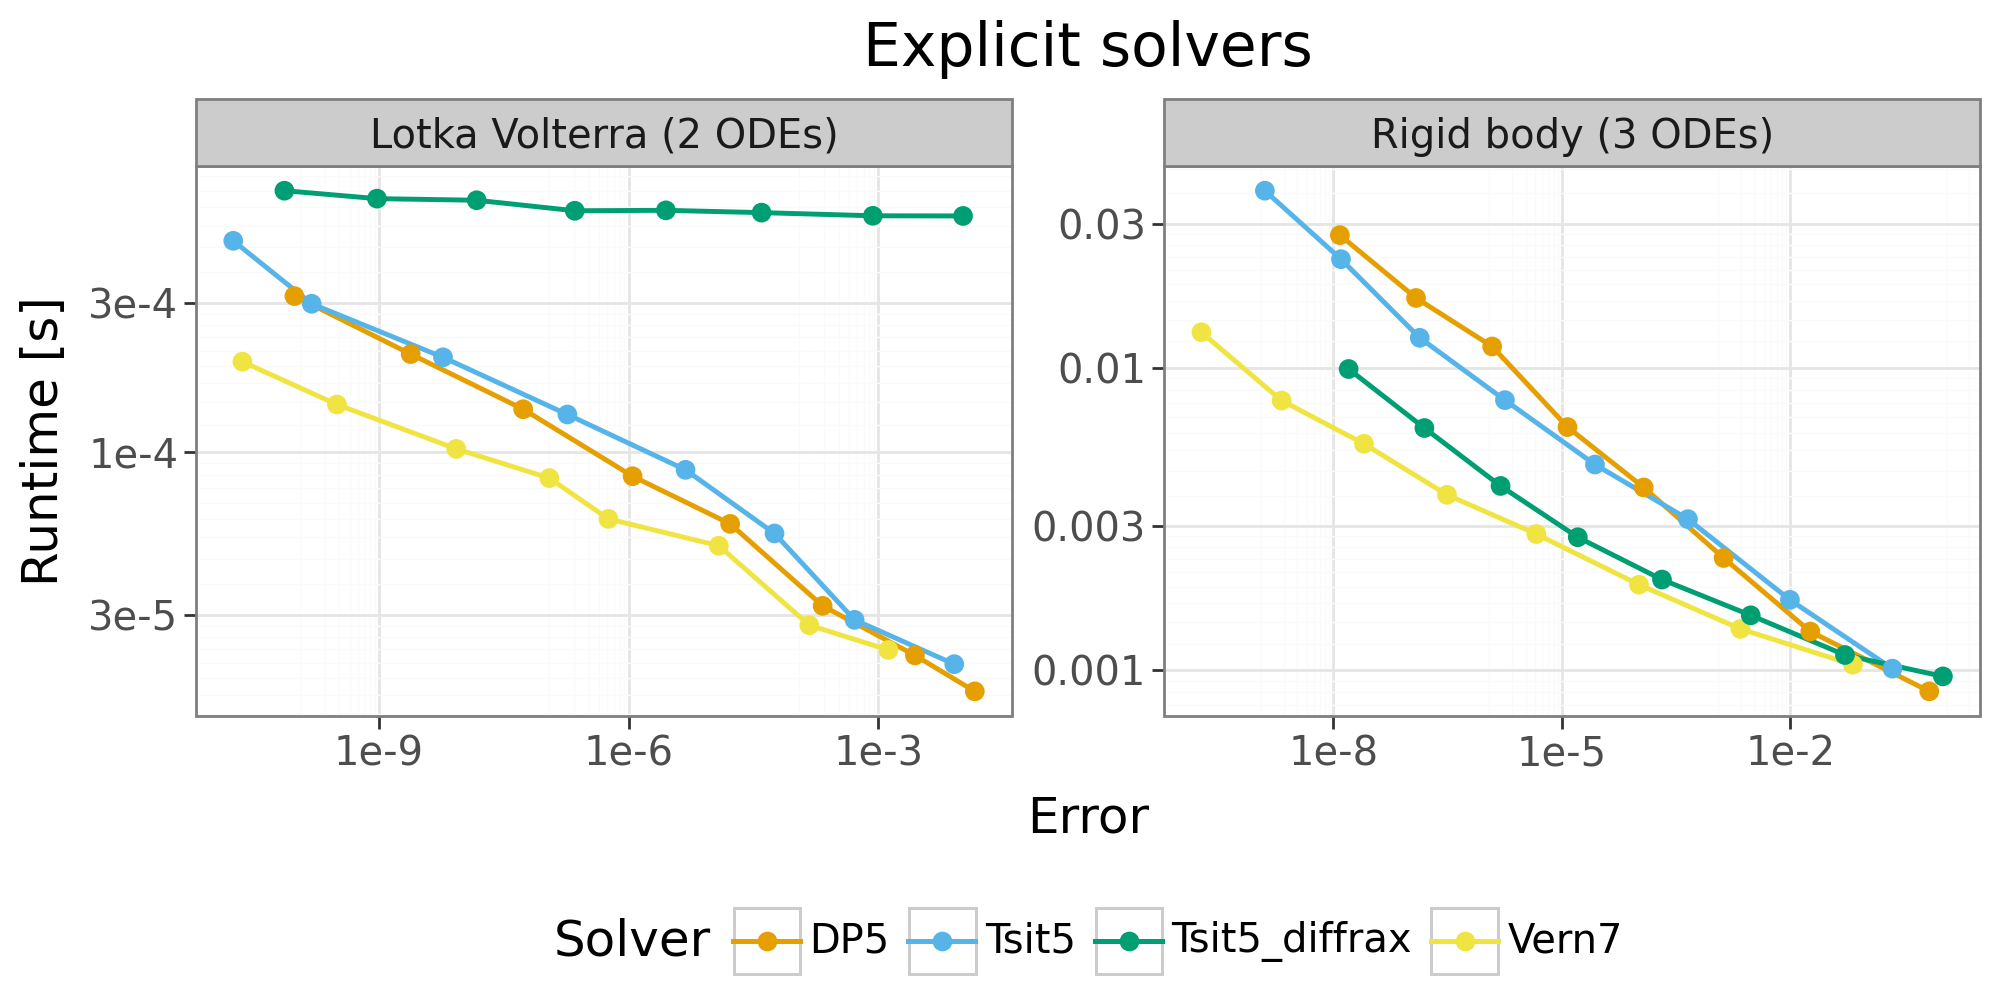

In [4]:
# plotnine is a good ggplot clone, and if you are in Python and miss ggplot 
# I can recommend plotnine
import pandas as pd
import plotnine as p9

cb_palette = ["#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", 
              "#D55E00", "#CC79A7", "#999999"]

df_lv = pd.read_csv("Intermediate/Benchmark_solvers/Runtime_LotkaVolterra.csv")
df_lv["model"] = "Lotka Volterra (2 ODEs)"
df_rb = pd.read_csv("Intermediate/Benchmark_solvers/Runtime_RigidBody.csv")
df_rb["model"] = "Rigid body (3 ODEs)"
df_plot = pd.concat([df_lv, df_rb], ignore_index = True)

(p9.ggplot(df_plot, p9.aes("error", "runtime", color="solver")) +
 p9.geom_line(size=1.0) +
 p9.geom_point(size=3.0) +
 p9.facet_wrap("~model", scales="free") +
 p9.scale_y_log10() +
 p9.scale_x_log10() +
 p9.scale_color_manual(values=cb_palette, name = "Solver") +
 p9.labs(x = "Error", y = "Runtime [s]", title = "Explicit solvers") +
 p9.theme_bw(base_size=18) + 
 p9.theme(figure_size=(10, 5), 
          legend_position="bottom"))

Overall, for both problems, the Julia Vern7 solver is the most efficient. The diffrax Tsit5 solver also performs quite well compared to its counterpart. Regarding the stiff models:

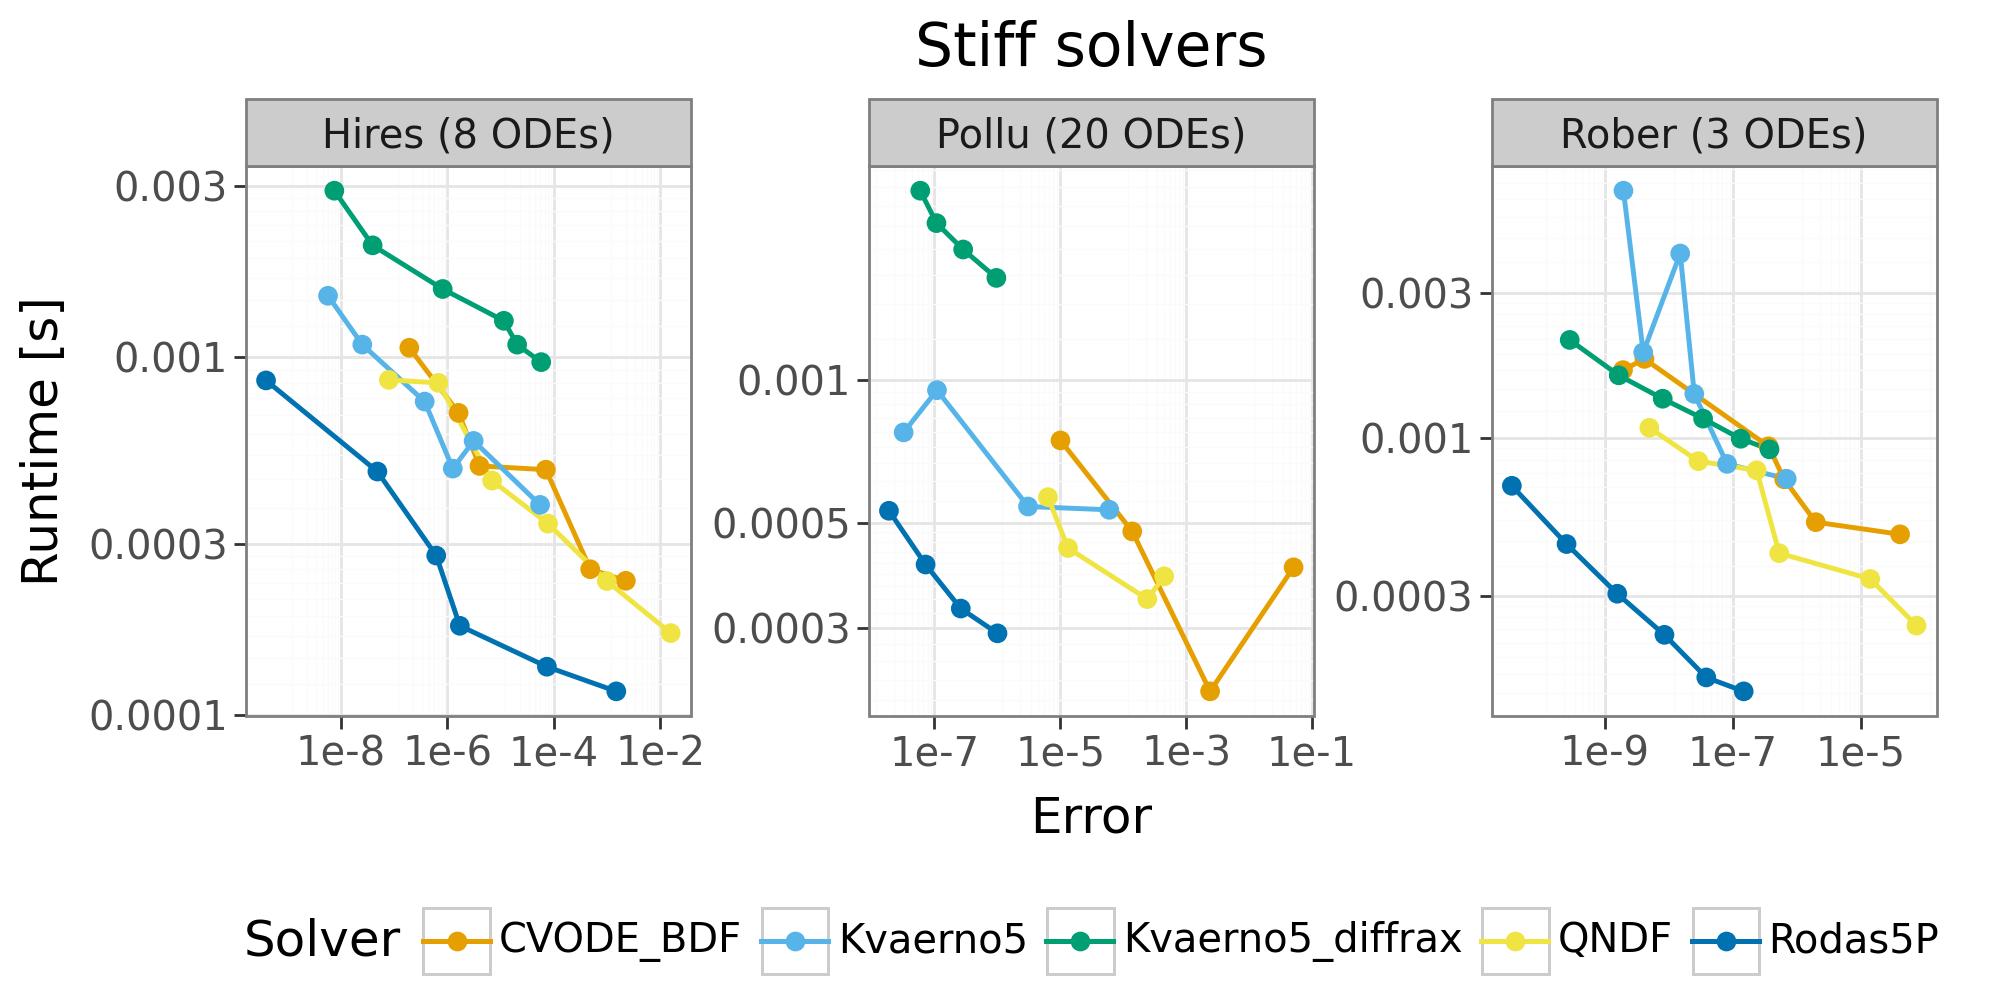

In [5]:
df_ro = pd.read_csv("Intermediate/Benchmark_solvers/Runtime_Rober.csv")
df_ro["model"] = "Rober (3 ODEs)"
df_hi = pd.read_csv("Intermediate/Benchmark_solvers/Runtime_Hires.csv")
df_hi["model"] = "Hires (8 ODEs)"
df_po = pd.read_csv("Intermediate/Benchmark_solvers/Runtime_Pollu.csv")
df_po["model"] = "Pollu (20 ODEs)"
df_plot = pd.concat([df_ro, df_hi, df_po], ignore_index = True)

(p9.ggplot(df_plot, p9.aes("error", "runtime", color="solver")) +
 p9.geom_line(size=1.0) +
 p9.geom_point(size=3.0) +
 p9.facet_wrap("~model", scales="free", ncol=3) +
 p9.scale_y_log10() +
 p9.scale_x_log10() +
 p9.scale_color_manual(values=cb_palette, name = "Solver") +
 p9.labs(x = "Error", y = "Runtime [s]", title = "Stiff solvers") +
 p9.theme_bw(base_size=18) + 
 p9.theme(figure_size=(10, 5), 
          legend_position="bottom"))

The Rosenbrock Rodas5P solver in Julia performs best. This is expected as our earlier benchmarks show that for smaller problems it excels. Regarding diffrax, it performs well for the smallest Rober models. However, when dealing with larger models such as Hires (which involves 8 ODEs) and Pollu (comprising 20 ODEs), Julia's stiff solvers noticeably outperform diffrax, which is a bit worrying.

The reason Julia performs better for the larger models might be because of the linear-solve. Unlike diffrax that by default uses a LU factorization via lineax, Julia employs a recursive LU algorithm, which has been shown to be efficient compared to a standard LU, for details the [RecursiveFactorization.jl repository](https://github.com/JuliaLinearAlgebra/RecursiveFactorization.jl).

Additionally, in the Julia ecosystem the Jacobians are computed using efficient coloring approaches. This technique allows for more efficient calculation of derivatives compared to the naive forward-mode differentiation which I think is used in diffrax.

#### Conclusions

The results highlights that Julia's ODE solvers excel for smaller models, and given that ForwardDiff is a mature package (see discussion above), I do not expect diffrax to outperform Julia in gradient computations for smaller models with few parameters. However, for computing the Hessian, diffrax might still hold an advantage due to its reverse-over-forward approach, which scales better than the forward-over-forward approach in Julia. That is, it might be the best option for Hessian based parameter estimation.

For larger stiff models, diffrax could probably benefit from improvements in linear-solving algorithms. Its performance needs to be further evaluated for larger models where runtime differences can be larger between software. Specifically, what I am worried about given results above is that despite diffrax not requiring the solution of the adjoint ODE (which is time-consuming), it might still not outperform tools like AMICI for large stiff models due to potentially slow forward pass. To test diffrax for larger models, a SBML importer is needed. 

### Gradient computations for UDEs

To benchmark UDE gradient computation times I considered the two models in the README. For the Lotka Volterra model we have;

| Model          | Software | Loss [ms] | Grad [ms] | Hessian |
|----------------|----------|-----------|-----------|---------|
| Lotka-Volterra | Julia    | 2.7       | 24        | 1490    |
| Lotka-Volterra | diffrax  | 1.3       | 10        | 28      |

and for the SIR model:

| Model | Software | Loss [ms] | Grad [ms] | Hessian |
|-------|----------|-----------|-----------|---------|
| SIR   | Julia    | 4.4       | 110       | 4400    |
| SIR   | diffrax  | 1.3       | 16        | 68      |

Diffrax shows a noticeable speed advantage in computing the loss, likely due to Jax's efficiency in evaluating feed-forward neural networks within the model. Additionally, gradient computations are faster, particularly for the larger SIR model.

#### Conclusions

For UDEs, diffrax appears to be the best option. These models typically contain too many parameters for a forward-mode AD approach to be practical. In addition, as diffrax's "discretize-then-optimize" approach does not require solving an adjoint ODE, it likely performs better than Julia. This advantage is expected to be even more significant in stiff models, as our benchmarks have indicated that SciMLSensitivity is unreliable for stiff models. However, we should not generalize these results to claim that diffrax is the most efficient for computing gradients in large stiff ODE models. The speed at which diffrax can perform the forward pass for these models remains uncertain, and it is possible that AMICI could still be faster given the ODE solver benchmarks above.

Given that computing the Hessian is feasible with Diffrax, the question is how to best use it. There are a few approaches inspired by the [adaHessian](https://ojs.aaai.org/index.php/AAAI/article/view/17275) and [Sophia](https://arxiv.org/abs/2305.14342) methods:

1. **Newton's Method with Hessian Pre-conditioning**: Step in the direction of the Newton update $\nabla G \cdot H^{-1}$ rather than the gradient direction alone. The problem is that this is not a guaranteed descent direction, so an implementation would require a check to validate that the Hessian is negative definite at each step. Additionally, this approach does not accommodate momentum.
2. **Implementing the Sophia Method**: The [Sophia](https://arxiv.org/abs/2305.14342) uses a diagonal approximation of the Hessian for updates. Instead, we could leverage the true Hessian diagonal. Given the flexibility of optax, implementation should be quite straightforward. It should be noted that computing the full Hessian is as expansive as computing its diagonal.
3. **Trust-Region Optimization**: A traditional full-batch trust-region approach could also be relevant to test. For this Fides can be used.

## Going forward

I think diffrax shows great potential as a backend for systems biology toolboxes. It could excel with respect to:

1. **Hessian based parameter estimation**: diffrax is particularly effective at computing Hessian. This can make parameter estimation more efficient.
2. **Parameter estimation for larger models**: The scalable adjoint method of diffrax can be the most efficient for large models.
3. **UDEs**: As shown above, the discretize-then-optimize seem to be the most efficient approach for UDEs. 

However, for diffrax to be useful in systems biology, the efficiency of the forward solve is essential. Based on current performance with models like Pollu, several improvements could enhance diffrax's capabilities. Enhancements in lineax, such as enabling users to provide custom Jacobians, could help, as well as support for sparse Jacobian. Moreover, diffrax could benefit from access to stiff solvers like Rosenbrock (smaller models) and multi-step BDF solver (larger models). 

Diffrax is probably not the best software for scenarios where a data-driven model is not directly integrated into the model equations but instead feeds into the model (e.g. deep mechanistic models). In these cases, the ODE solver's adjoint can be provided via a rule, and the ODE can be solved using platforms like Julia. Given Julia's support for in-place mutating operations and mature ecosystem I do not imagine diffrax to outperform Julia in gradient based workflows for smaller models.

Going forward, the following actions should be taken to evaluate diffrax:

- **Benchmarking stiff solvers for larger models**: Conducting more comprehensive benchmarks of stiff solvers on larger models to see how fast diffrax is, and how often it fails to solve the ODE.
- **Evaluating Hessian runtime for classical parameter estimation problems**: As mentioned above, this is one of the areas diffrax could shine.
- **Comparing gradient runtime for UDEs**: As mentioned above, this is one of the areas where diffrax could shine.
- **Implementing SBML and PEtab Importers in Diffrax**: This will make it easier to use and benchmark diffrax.
